In [2]:
!pip install requests beautifulsoup4 pandas matplotlib seaborn textblob -q

In [3]:
import requests
from bs4 import BeautifulSoup
import pandas as pd

data = []

for page in range(1, 11):
    url = f"https://quotes.toscrape.com/page/{page}/"
    soup = BeautifulSoup(requests.get(url).text, "html.parser")

    for q in soup.find_all("div", class_="quote"):
        data.append({
            "Quote": q.find("span", class_="text").text.strip(),
            "Author": q.find("small", class_="author").text.strip(),
            "Tags": ", ".join(t.text for t in q.find_all("a", class_="tag"))
        })

df = pd.DataFrame(data)
df.to_csv("quotes_dataset.csv", index=False)

print("Scraping complete!")
print(df.head())

Scraping complete!
                                               Quote           Author  \
0  “The world as we have created it is a process ...  Albert Einstein   
1  “It is our choices, Harry, that show what we t...     J.K. Rowling   
2  “There are only two ways to live your life. On...  Albert Einstein   
3  “The person, be it gentleman or lady, who has ...      Jane Austen   
4  “Imperfection is beauty, madness is genius and...   Marilyn Monroe   

                                           Tags  
0        change, deep-thoughts, thinking, world  
1                            abilities, choices  
2  inspirational, life, live, miracle, miracles  
3              aliteracy, books, classic, humor  
4                    be-yourself, inspirational  


In [4]:
print("Rows and Columns:", df.shape)
print(df.head())

Rows and Columns: (100, 3)
                                               Quote           Author  \
0  “The world as we have created it is a process ...  Albert Einstein   
1  “It is our choices, Harry, that show what we t...     J.K. Rowling   
2  “There are only two ways to live your life. On...  Albert Einstein   
3  “The person, be it gentleman or lady, who has ...      Jane Austen   
4  “Imperfection is beauty, madness is genius and...   Marilyn Monroe   

                                           Tags  
0        change, deep-thoughts, thinking, world  
1                            abilities, choices  
2  inspirational, life, live, miracle, miracles  
3              aliteracy, books, classic, humor  
4                    be-yourself, inspirational  


In [5]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Quote   100 non-null    object
 1   Author  100 non-null    object
 2   Tags    100 non-null    object
dtypes: object(3)
memory usage: 2.5+ KB
None


In [6]:
print(df.isnull().sum())

Quote     0
Author    0
Tags      0
dtype: int64


In [7]:
print("Duplicates:", df.duplicated().sum())

Duplicates: 0


In [8]:
print(df["Author"].value_counts().head(10))

Author
Albert Einstein      10
J.K. Rowling          9
Marilyn Monroe        7
Dr. Seuss             6
Mark Twain            6
Jane Austen           5
C.S. Lewis            5
Bob Marley            3
Mother Teresa         2
Eleanor Roosevelt     2
Name: count, dtype: int64


In [9]:
tags = df["Tags"].str.split(", ").explode()
print(tags.value_counts().head(10))

Tags
love                    14
inspirational           13
life                    13
humor                   12
books                   11
reading                  7
friendship               5
friends                  4
truth                    4
attributed-no-source     3
Name: count, dtype: int64


In [10]:
tags = df["Tags"].str.split(", ").explode()
print(tags.value_counts().head(10))

Tags
love                    14
inspirational           13
life                    13
humor                   12
books                   11
reading                  7
friendship               5
friends                  4
truth                    4
attributed-no-source     3
Name: count, dtype: int64


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

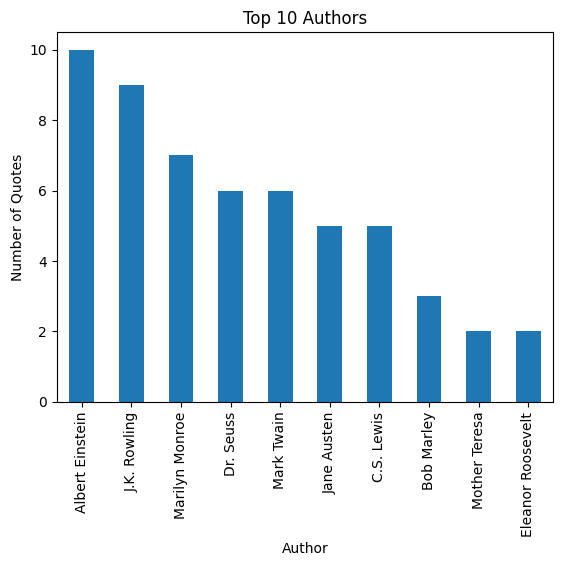

In [12]:
df["Author"].value_counts().head(10).plot(kind="bar")
plt.title("Top 10 Authors")
plt.xlabel("Author")
plt.ylabel("Number of Quotes")
plt.show()

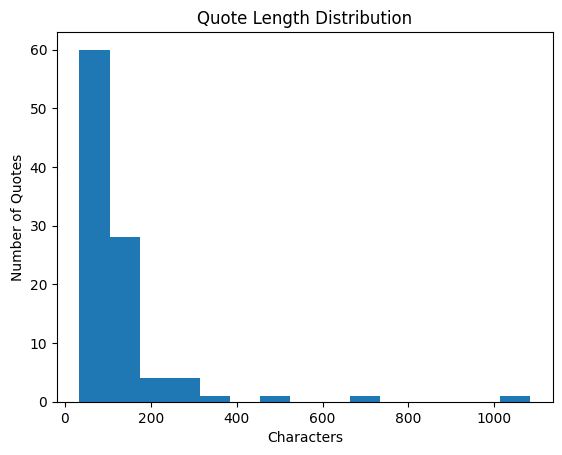

In [13]:
df["Length"] = df["Quote"].str.len()

plt.hist(df["Length"], bins=15)
plt.title("Quote Length Distribution")
plt.xlabel("Characters")
plt.ylabel("Number of Quotes")
plt.show()

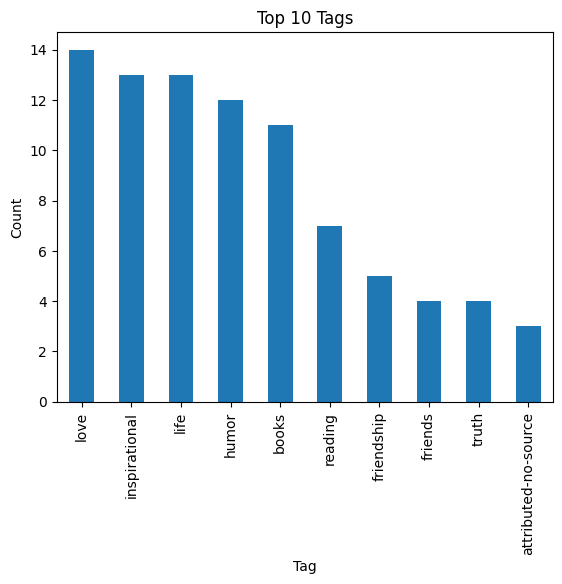

In [14]:
tags.value_counts().head(10).plot(kind="bar")
plt.title("Top 10 Tags")
plt.xlabel("Tag")
plt.ylabel("Count")
plt.show()

In [15]:
from textblob import TextBlob

In [16]:
df["Polarity"] = df["Quote"].apply(
    lambda x: TextBlob(x).sentiment.polarity
)

In [17]:
def sentiment(x):
    if x > 0:
        return "Positive"
    elif x < 0:
        return "Negative"
    else:
        return "Neutral"

df["Sentiment"] = df["Polarity"].apply(sentiment)

print(df[["Quote", "Polarity", "Sentiment"]].head(10))

                                               Quote  Polarity Sentiment
0  “The world as we have created it is a process ...  0.000000   Neutral
1  “It is our choices, Harry, that show what we t...  0.300000  Positive
2  “There are only two ways to live your life. On...  0.003788  Positive
3  “The person, be it gentleman or lady, who has ... -0.050000  Negative
4  “Imperfection is beauty, madness is genius and... -0.277778  Negative
5  “Try not to become a man of success. Rather be...  0.300000  Positive
6  “It is better to be hated for what you are tha...  0.100000  Positive
7  “I have not failed. I've just found 10,000 way...  0.250000  Positive
8  “A woman is like a tea bag; you never know how...  0.341667  Positive
9  “A day without sunshine is like, you know, nig...  0.000000   Neutral


In [18]:
print(df["Sentiment"].value_counts())

Sentiment
Positive    54
Neutral     28
Negative    18
Name: count, dtype: int64


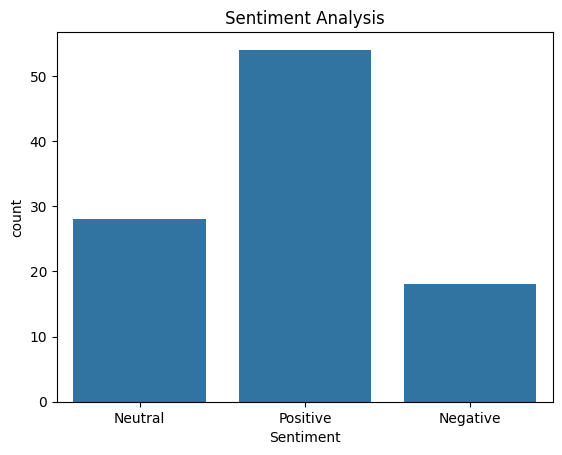

In [19]:
sns.countplot(data=df, x="Sentiment")
plt.title("Sentiment Analysis")
plt.show()

In [20]:
df.to_csv("final_dataset.csv", index=False)
print("Final dataset saved!")

Final dataset saved!


In [1]:
!git config --global user.name "parim22"
!git config --global user.email "24mahurep@rbunagpur.in"

In [2]:
!git clone https://github.com/parim22/Code_Alpha_DA_project.git


Cloning into 'Code_Alpha_DA_project'...
